# UDAI 2026 · Card Churn Challenge — pipeline gọn

Dự đoán **xác suất** khách hàng đóng thẻ tín dụng trong 3 tháng sau ngày chốt 30/06/2026 (`churn_3m = 1` nếu đóng trước 30/09/2026).

| Tiêu chí (starter + mô tả dữ liệu) | Trong notebook |
|---|---|
| Chấm bằng **ROC AUC** — chỉ xét thứ tự xếp hạng khách | Chọn mô hình theo AUC của 5-fold CV |
| Nộp `customer_id,churn_3m` cho đủ 8.000 khách của `test.csv`, giá trị là xác suất | `save_submission` kiểm tra ID, cột, giá trị trong [0, 1] |
| Dữ liệu bẩn có chủ đích | Mục 2 đếm và sửa từng loại lỗi, áp dụng **cùng quy tắc** cho train và test |
| Validate bằng cross-validation, không dựa vào public leaderboard | `StratifiedKFold` 5 fold, dự đoán out-of-fold (OOF) |

Mốc: starter (logistic, chỉ cột số) ≈ 0.73 AUC.

**Chạy trên Kaggle:** Import Notebook → Add Input › Competitions › *UDAI 2026 · Card Churn Challenge* → Run All. Chỉ cần CPU, chưa đến 1 phút.

## 1. Thư viện và dữ liệu

In [1]:
import glob
import unicodedata
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, balanced_accuracy_score, brier_score_loss,
                             confusion_matrix, f1_score, log_loss, precision_recall_curve, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

warnings.filterwarnings('ignore', category=FutureWarning)
SEED = 42
ID, TARGET = 'customer_id', 'churn_3m'
SNAPSHOT = pd.Timestamp('2026-06-30')
COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e5e4e0', 'grid.linewidth': 0.6,
                     'axes.axisbelow': True, 'lines.linewidth': 2})

# Bộ Churn là train.csv có cột churn_3m (train.csv của Cafe không có); ưu tiên thư mục có test.csv.
hits = [Path(p).parent for p in glob.glob('/kaggle/input/**/train.csv', recursive=True)
        + glob.glob('train.csv') + glob.glob('churn/train.csv')
        if TARGET in pd.read_csv(p, nrows=0).columns]
if not hits:
    raise FileNotFoundError('Không thấy train.csv có cột churn_3m. Trên Kaggle: Add Input › Competitions › UDAI 2026 · Card Churn Challenge')
DATA = sorted(hits, key=lambda p: not (p / 'test.csv').exists())[0]
OUT = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('outputs_churn')
OUT.mkdir(exist_ok=True)

train_raw = pd.read_csv(DATA / 'train.csv')
test = pd.read_csv(DATA / 'test.csv') if (DATA / 'test.csv').exists() else None
sample = pd.read_csv(DATA / 'sample_submission.csv')
print('Dữ liệu:', DATA.resolve(), '| Kết quả lưu ở:', OUT.resolve())
print('train:', train_raw.shape, '| test:', None if test is None else test.shape, '| sample:', sample.shape)
print(f'Tỷ lệ churn trong train: {train_raw[TARGET].mean():.1%}')

Dữ liệu: C:\Users\Ngoc Hieu\Desktop\colabnhi\churn | Kết quả lưu ở: C:\Users\Ngoc Hieu\Desktop\colabnhi\outputs_churn
train: (12120, 24) | test: None | sample: (8000, 2)
Tỷ lệ churn trong train: 11.7%


## 2. Kiểm tra chất lượng dữ liệu

Cùng một bộ kiểm tra cho train và test (lỗi nằm ở cả hai). Lưu thành `data_quality.csv`.

In [2]:
def quality_report(df):
    open_text = df.open_date.astype('string')
    return pd.Series({
        'dòng trùng hoàn toàn': df.duplicated().sum(),
        'customer_id trùng sau khi bỏ dòng trùng': df.drop_duplicates()[ID].duplicated().sum(),
        'gender: số cách viết': df.gender.nunique(),
        'province: số cách viết': df.province.nunique(),
        'occupation: số cách viết': df.occupation.nunique(),
        'currency: viết thường "vnd"': (df.currency == 'vnd').sum(),
        'bank_code: số giá trị (1 = cột hằng)': df.bank_code.nunique(),
        'income_month ghi theo VND (≥ 100.000)': (df.income_month >= 1e5).sum(),
        'credit_limit ghi theo VND (≥ 100.000)': (df.credit_limit >= 1e5).sum(),
        'age ngoài 18–100 (0, 1, 150, 200, 999)': (df.age.notna() & ~df.age.between(18, 100)).sum(),
        'utilization_6m = -1 (mã thiếu)': (df.utilization_6m < 0).sum(),
        'utilization_6m > 2 (9.99, 15: mã lỗi)': (df.utilization_6m > 2).sum(),
        'open_date dạng dd/mm/yyyy': open_text.str.contains('/', na=False).sum(),
        'open_date dạng yyyymmdd': open_text.str.fullmatch(r'\d{8}', na=False).sum(),
        'txn_amount_3m âm (hoàn tiền > chi tiêu, giữ nguyên)': (df.txn_amount_3m < 0).sum(),
    })


quality = pd.DataFrame({'train': quality_report(train_raw)})
if test is not None:
    quality['test'] = quality_report(test)
display(quality)
quality.to_csv(OUT / 'data_quality.csv')
print('Tỷ lệ thiếu (train):')
display(train_raw.isna().mean().loc[lambda s: s > 0].sort_values(ascending=False).round(3).to_frame('thiếu'))

,train
dòng trùng hoàn toàn,120
customer_id trùng sau khi bỏ dòng trùng,0
gender: số cách viết,8
province: số cách viết,41
occupation: số cách viết,15
"currency: viết thường ""vnd""",60
bank_code: số giá trị (1 = cột hằng),1
income_month ghi theo VND (≥ 100.000),106
credit_limit ghi theo VND (≥ 100.000),247
"age ngoài 18–100 (0, 1, 150, 200, 999)",69


Tỷ lệ thiếu (train):


,thiếu
other_bank_cards,0.203
income_month,0.129
app_logins_30d,0.125
salary_via_bank,0.059
occupation,0.051
last_contact_channel,0.042
age,0.033
gender,0.019
province,0.017
open_date,0.006


### Cách xử lý

- **Dòng trùng:** bỏ 120 dòng trùng hoàn toàn; sau đó mỗi `customer_id` là duy nhất.
- **Chữ:** bỏ dấu, chữ thường, gộp cách viết: `F`/`female`/`Nữ` → `female`; `TP.HCM`/`HCM`/`Hồ Chí Minh` → `ho chi minh`; `Self-employed` → `self_employed`.
- **Sai đơn vị:** `income_month` và `credit_limit` ≥ 100.000 rõ ràng là VND (ví dụ 29.200.000) → chia 1.000.000 về triệu VND.
- **Mã lỗi → thiếu:** tuổi ngoài 18–100; `utilization_6m` = −1 hoặc > 2. Giá trị 1,00–1,05 (vượt hạn mức nhẹ) được giữ.
- **Ngày mở thẻ:** đọc 3 định dạng (`yyyy-mm-dd`, `dd/mm/yyyy`, `yyyymmdd`) → thâm niên và **tháng mở thẻ**.
- **Bỏ cột hằng:** `bank_code` (chỉ VB01), `currency` (chỉ VND).
- **Giá trị thiếu giữ nguyên là NaN:** việc thiếu có thể mang thông tin (thiếu `app_logins_30d` → churn 17% so với 12%).
  Cây quyết định xử lý NaN trực tiếp; logistic điền trung vị + thêm cột đánh dấu thiếu, học **bên trong từng fold**.

In [3]:
def plain(value):
    if pd.isna(value):
        return np.nan
    value = str(value).strip().lower().replace('đ', 'd')
    value = ''.join(c for c in unicodedata.normalize('NFD', value) if unicodedata.category(c) != 'Mn')
    return ' '.join(value.split())


PROVINCE = {'tp.hcm': 'ho chi minh', 'tp hcm': 'ho chi minh', 'hcm': 'ho chi minh', 'hn': 'ha noi',
            'hanoi': 'ha noi', 'danang': 'da nang', 'br-vt': 'ba ria - vung tau'}


def clean(df):
    X = df.drop(columns=[ID, TARGET, 'bank_code', 'currency'], errors='ignore').copy()
    X['gender'] = X.gender.map(plain).replace({'f': 'female', 'nu': 'female', 'm': 'male', 'nam': 'male'})
    X['province'] = X.province.map(plain).replace(PROVINCE)
    X['occupation'] = X.occupation.map(plain).str.replace(r'[\s-]+', '_', regex=True)
    X['salary_via_bank'] = X.salary_via_bank.map({'Y': 1, 'N': 0})
    for col in ['income_month', 'credit_limit']:
        X[col] = X[col].where(X[col] < 1e5, X[col] / 1e6)
    X['age'] = X.age.where(X.age.between(18, 100))
    X['utilization_6m'] = X.utilization_6m.where(X.utilization_6m.between(0, 2))

    text = X.pop('open_date').astype('string')
    opened = pd.to_datetime(text, format='%Y-%m-%d', errors='coerce')
    for fmt in ['%d/%m/%Y', '%Y%m%d']:
        opened = opened.fillna(pd.to_datetime(text, format=fmt, errors='coerce'))
    opened = opened.where(opened <= SNAPSHOT)
    X['tenure_months'] = (SNAPSHOT - opened).dt.days / 30.44
    X['open_month'] = opened.dt.month
    # Phí thường niên thu vào tháng kỷ niệm mở thẻ: mở thẻ tháng 7–9 và không được miễn phí
    # → phí đến hạn đúng trong 3 tháng cần dự đoán (xem biểu đồ bên dưới).
    X['fee_due_3m'] = (X.open_month.isin([7, 8, 9]) & X.annual_fee_waived.eq(0)).astype(float).where(opened.notna())
    return X


train = train_raw.drop_duplicates().reset_index(drop=True)
assert train[ID].is_unique and set(train[TARGET].unique()) == {0, 1}
X = clean(train)
y = train[TARGET].to_numpy()
CATS = ['gender', 'province', 'occupation', 'card_type', 'last_contact_channel']
NUMS = [c for c in X.columns if c not in CATS]
print('Sau làm sạch:', X.shape, '| số nhóm mỗi cột chữ:', X[CATS].nunique().to_dict())
pd.concat([train[[ID]], X, train[[TARGET]]], axis=1).to_csv(OUT / 'train_clean.csv', index=False)

Sau làm sạch: (12000, 22) | số nhóm mỗi cột chữ: {'gender': 2, 'province': 26, 'occupation': 6, 'card_type': 4, 'last_contact_channel': 4}


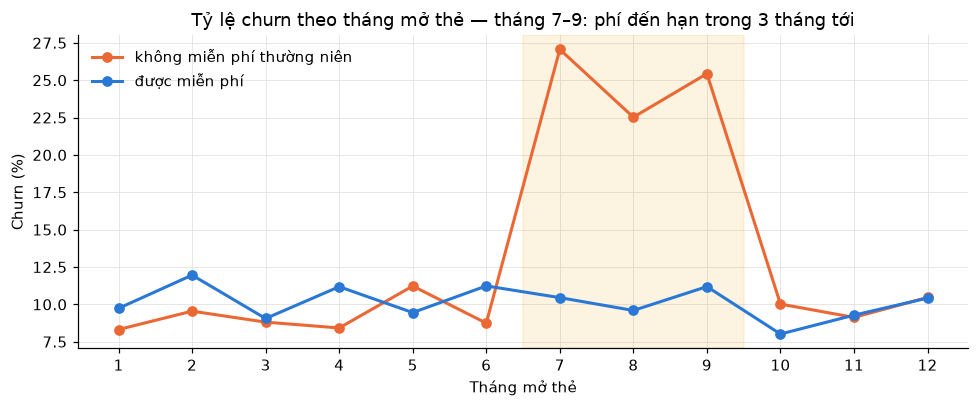

In [4]:
by_month = (pd.DataFrame({'month': X.open_month, 'waived': X.annual_fee_waived, 'churn': y})
            .groupby(['month', 'waived']).churn.mean().unstack())
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(by_month.index, 100 * by_month[0], color=COLORS[1], marker='o', label='không miễn phí thường niên')
ax.plot(by_month.index, 100 * by_month[1], color=COLORS[0], marker='o', label='được miễn phí')
ax.axvspan(6.5, 9.5, color='#eda100', alpha=0.12)
ax.set_xticks(range(1, 13))
ax.set(title='Tỷ lệ churn theo tháng mở thẻ — tháng 7–9: phí đến hạn trong 3 tháng tới',
       xlabel='Tháng mở thẻ', ylabel='Churn (%)')
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(OUT / 'churn_by_open_month.png', bbox_inches='tight')
plt.show()

## 3. Mô hình

| Mô hình | Mô tả |
|---|---|
| `baseline` | Đúng như starter: chỉ cột số **chưa làm sạch**, điền trung vị, logistic |
| `logistic` | Logistic trên dữ liệu đã làm sạch, mã hoá one-hot cột chữ |
| `boosting` | HistGradientBoosting cây nông (4 lá), học chậm — ít overfit với 12.000 khách |
| `blend` | 0.8 × `boosting` + 0.2 × `logistic` (trung bình xác suất) |

Mọi bước điền thiếu / chuẩn hoá / mã hoá nằm **trong pipeline**, nên mỗi fold chỉ học từ phần train của fold đó.

In [5]:
RAW_NUMS = train_raw.drop(columns=TARGET).select_dtypes('number').columns.tolist()


def baseline():
    pick = ColumnTransformer([('num', SimpleImputer(strategy='median'), RAW_NUMS)])
    return make_pipeline(pick, StandardScaler(), LogisticRegression(max_iter=2000))


def logistic():
    prep = ColumnTransformer([
        ('num', make_pipeline(SimpleImputer(strategy='median', add_indicator=True), StandardScaler()), NUMS),
        ('cat', make_pipeline(SimpleImputer(strategy='constant', fill_value='missing'),
                              OneHotEncoder(handle_unknown='ignore', min_frequency=20)), CATS)])
    return make_pipeline(prep, LogisticRegression(max_iter=3000, C=0.5))


def boosting():
    prep = ColumnTransformer([
        ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=np.nan), CATS),
        ('num', 'passthrough', NUMS)])
    return make_pipeline(prep, HistGradientBoostingClassifier(
        learning_rate=0.03, max_iter=400, max_leaf_nodes=4, min_samples_leaf=80, l2_regularization=5.0,
        categorical_features=list(range(len(CATS))), early_stopping=False, random_state=SEED))


MODELS = ['baseline', 'logistic', 'boosting', 'blend']
raw_X = train.drop(columns=[ID, TARGET])


def fit_predict(train_idx, predict_frames):
    """Fit all models on train rows; return {model: probabilities} for each (raw, clean) frame pair."""
    base = baseline().fit(raw_X.iloc[train_idx], y[train_idx])
    logit = logistic().fit(X.iloc[train_idx], y[train_idx])
    boost = boosting().fit(X.iloc[train_idx], y[train_idx])
    raw_new, clean_new = predict_frames
    p = {'baseline': base.predict_proba(raw_new)[:, 1],
         'logistic': logit.predict_proba(clean_new)[:, 1],
         'boosting': boost.predict_proba(clean_new)[:, 1]}
    p['blend'] = 0.8 * p['boosting'] + 0.2 * p['logistic']
    return p, boost

## 4. Chỉ số đánh giá

| Chỉ số | Ý nghĩa | Ghi chú |
|---|---|---|
| **ROC AUC** | Xác suất một khách churn được xếp rủi ro cao hơn một khách không churn | **Chỉ số chấm điểm Kaggle**; 0.5 = ngẫu nhiên |
| PR AUC (AP) | Độ chính xác trung bình khi tìm khách churn | Hữu ích khi churn hiếm (11,7%); mốc ngẫu nhiên = 0.117 |
| Log loss, Brier | Xác suất dự đoán có sát thực tế không | Thấp là tốt |
| **Accuracy** | % khách đoán đúng nhãn | Dễ gây hiểu nhầm: đoán "không ai churn" đã đúng 88% |
| **Precision** | Trong số khách bị báo churn, bao nhiêu % churn thật | Cao → ít gọi nhầm khách |
| **Recall** | Trong số khách churn thật, tìm ra được bao nhiêu % | Cao → ít bỏ sót |
| F1 | Trung bình điều hoà precision và recall | |
| Specificity | % khách không churn được nhận đúng | |
| Balanced accuracy | Trung bình recall của 2 lớp | Không bị ảnh hưởng bởi lệch lớp |

Các chỉ số có ngưỡng (accuracy → balanced accuracy) cần chọn ngưỡng xác suất để đổi thành nhãn 0/1.
Ta báo cáo ở ngưỡng 0.5 và ở **ngưỡng tối ưu F1** tìm trên dự đoán OOF. Ngưỡng **không ảnh hưởng điểm Kaggle** (AUC chỉ xét thứ tự).

In [6]:
def score_metrics(actual, prob):
    return {'ROC_AUC': roc_auc_score(actual, prob), 'PR_AUC': average_precision_score(actual, prob),
            'LogLoss': log_loss(actual, prob), 'Brier': brier_score_loss(actual, prob)}


def label_metrics(actual, prob, threshold):
    pred = (prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(actual, pred, labels=[0, 1]).ravel()
    return {'threshold': threshold, 'flagged_%': 100 * pred.mean(),
            'Accuracy': accuracy_score(actual, pred), 'Precision': precision_score(actual, pred, zero_division=0),
            'Recall': recall_score(actual, pred), 'F1': f1_score(actual, pred),
            'Specificity': tn / (tn + fp), 'Balanced_acc': balanced_accuracy_score(actual, pred),
            'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn}


def best_f1_threshold(actual, prob):
    precision, recall, thresholds = precision_recall_curve(actual, prob)
    f1 = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-12)
    return float(thresholds[np.argmax(f1)])

## 5. Cross-validation 5 fold

Cùng 5 fold cho mọi mô hình. Mỗi khách được dự đoán đúng một lần bởi mô hình **không nhìn thấy khách đó** (out-of-fold),
nên có thể tính mọi chỉ số trên toàn bộ 12.000 khách.

In [7]:
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(X, y))
oof = pd.DataFrame({ID: train[ID], 'actual': y})
for m in MODELS:
    oof[m] = np.nan
rows = []
for fold, (tr, va) in enumerate(folds, 1):
    probs, _ = fit_predict(tr, (raw_X.iloc[va], X.iloc[va]))
    for m, p in probs.items():
        oof.loc[va, m] = p
        rows.append({'fold': fold, 'model': m, **score_metrics(y[va], p)})
cv_metrics = pd.DataFrame(rows)

summary = []
for m in MODELS:
    folds_m = cv_metrics[cv_metrics.model == m]
    threshold = best_f1_threshold(y, oof[m])
    summary.append({'model': m, 'AUC_mean': folds_m.ROC_AUC.mean(), 'AUC_std': folds_m.ROC_AUC.std(),
                    **score_metrics(y, oof[m]),
                    **{f'{k}@0.5': v for k, v in label_metrics(y, oof[m], 0.5).items()
                       if k in ['Accuracy', 'Precision', 'Recall', 'F1']},
                    **{f'{k}@bestF1': v for k, v in label_metrics(y, oof[m], threshold).items()
                       if k in ['threshold', 'Accuracy', 'Precision', 'Recall', 'F1', 'Specificity', 'Balanced_acc']}})
summary = pd.DataFrame(summary).set_index('model')
BEST = summary.drop(index='baseline').AUC_mean.idxmax()

cv_metrics.to_csv(OUT / 'cv_metrics_by_fold.csv', index=False)
summary.to_csv(OUT / 'cv_metrics_summary.csv')
oof.to_csv(OUT / 'oof_predictions.csv', index=False)

print('ROC AUC theo fold:')
display(cv_metrics.pivot(index='model', columns='fold', values='ROC_AUC').loc[MODELS]
        .assign(mean=lambda t: t.mean(axis=1), std=lambda t: t.iloc[:, :5].std(axis=1)).round(4))
print('Chỉ số xếp hạng / xác suất (OOF):')
display(summary[['AUC_mean', 'AUC_std', 'PR_AUC', 'LogLoss', 'Brier']].round(4))
print('Chỉ số theo nhãn — ngưỡng 0.5 và ngưỡng tối ưu F1:')
display(summary.filter(like='@').round(3))
print(f'Mô hình tốt nhất theo AUC: {BEST}. Mốc "đoán tất cả không churn": accuracy {1 - y.mean():.3f}, recall 0.')

ROC AUC theo fold:


fold,1,2,3,4,5,mean,std
model,,,,,,,
baseline,0.7219,0.7114,0.7391,0.7420,0.7263,0.7281,0.0126
logistic,0.7700,0.7673,0.7986,0.7958,0.7916,0.7847,0.0149
boosting,0.8008,0.7956,0.8244,0.8141,0.8159,0.8102,0.0117
blend,0.8007,0.7956,0.8239,0.8153,0.8160,0.8103,0.0117


Chỉ số xếp hạng / xác suất (OOF):


,AUC_mean,AUC_std,PR_AUC,LogLoss,Brier
model,,,,,
baseline,0.7281,0.0126,0.2864,0.3258,0.0945
logistic,0.7847,0.0149,0.4056,0.2983,0.0859
boosting,0.8102,0.0117,0.4749,0.2820,0.0809
blend,0.8103,0.0117,0.4752,0.2825,0.0811


Chỉ số theo nhãn — ngưỡng 0.5 và ngưỡng tối ưu F1:


,Accuracy@0.5,Precision@0.5,Recall@0.5,F1@0.5,threshold@bestF1,Accuracy@bestF1,Precision@bestF1,Recall@bestF1,F1@bestF1,Specificity@bestF1,Balanced_acc@bestF1
model,,,,,,,,,,,
baseline,0.884,0.618,0.033,0.063,0.154,0.766,0.262,0.547,0.354,0.795,0.671
logistic,0.890,0.620,0.147,0.237,0.225,0.852,0.391,0.478,0.430,0.901,0.690
boosting,0.896,0.734,0.174,0.282,0.220,0.859,0.421,0.539,0.473,0.902,0.720
blend,0.896,0.758,0.163,0.268,0.254,0.875,0.468,0.481,0.474,0.927,0.704


Mô hình tốt nhất theo AUC: blend. Mốc "đoán tất cả không churn": accuracy 0.883, recall 0.


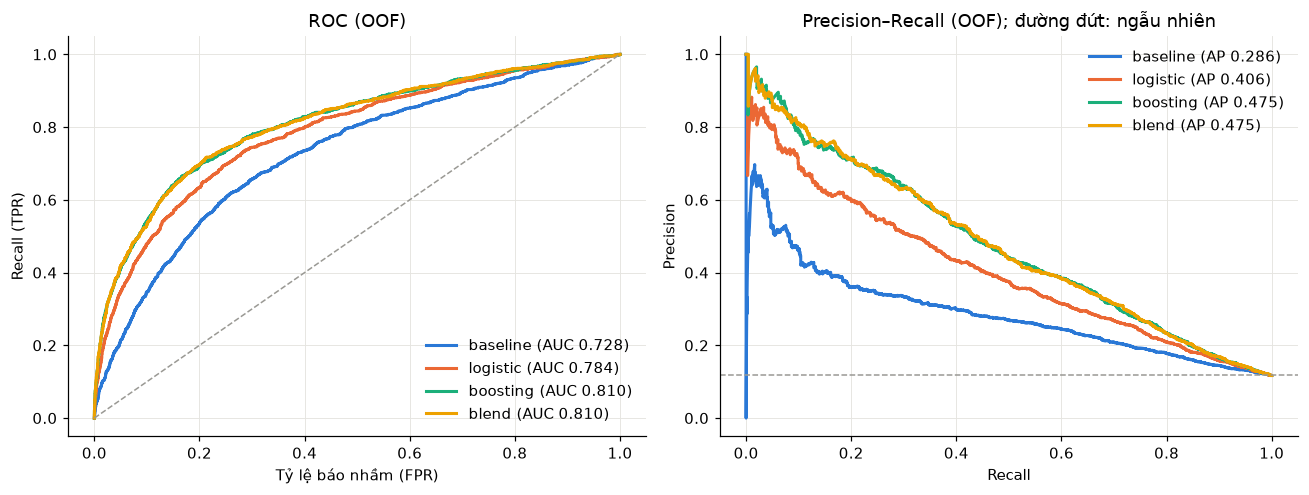

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for color, m in zip(COLORS, MODELS):
    fpr, tpr, _ = roc_curve(y, oof[m])
    axes[0].plot(fpr, tpr, color=color, label=f'{m} (AUC {roc_auc_score(y, oof[m]):.3f})')
    precision, recall, _ = precision_recall_curve(y, oof[m])
    axes[1].plot(recall, precision, color=color, label=f'{m} (AP {average_precision_score(y, oof[m]):.3f})')
axes[0].plot([0, 1], [0, 1], color='#9a9994', linestyle='--', linewidth=1)
axes[0].set(title='ROC (OOF)', xlabel='Tỷ lệ báo nhầm (FPR)', ylabel='Recall (TPR)')
axes[1].axhline(y.mean(), color='#9a9994', linestyle='--', linewidth=1)
axes[1].set(title='Precision–Recall (OOF); đường đứt: ngẫu nhiên', xlabel='Recall', ylabel='Precision')
for ax in axes:
    ax.legend(frameon=False, loc='lower right' if ax is axes[0] else 'upper right')
fig.tight_layout()
fig.savefig(OUT / 'roc_pr_curves.png', bbox_inches='tight')
plt.show()

## 6. Chọn ngưỡng và ma trận nhầm lẫn

Bảng dưới cho mô hình tốt nhất ở nhiều ngưỡng: ngưỡng thấp → tìm được nhiều khách churn hơn (recall cao) nhưng gọi nhầm nhiều hơn.
Ngưỡng tối ưu F1 được tìm trên chính dự đoán OOF nên hơi lạc quan.

,threshold,flagged_%,Accuracy,Precision,Recall,F1,Specificity,Balanced_acc,TP,FP,FN,TN
0,0.100,35.992,0.705,0.252,0.776,0.381,0.695,0.736,1090,3229,315,7366
1,0.150,23.625,0.804,0.334,0.674,0.447,0.822,0.748,947,1888,458,8707
2,0.200,16.958,0.848,0.397,0.574,0.469,0.884,0.729,807,1228,598,9367
3,0.300,9.183,0.888,0.529,0.415,0.465,0.951,0.683,583,519,822,10076
4,0.500,2.517,0.896,0.758,0.163,0.268,0.993,0.578,229,73,1176,10522
5,0.254,12.042,0.875,0.468,0.481,0.474,0.927,0.704,676,769,729,9826


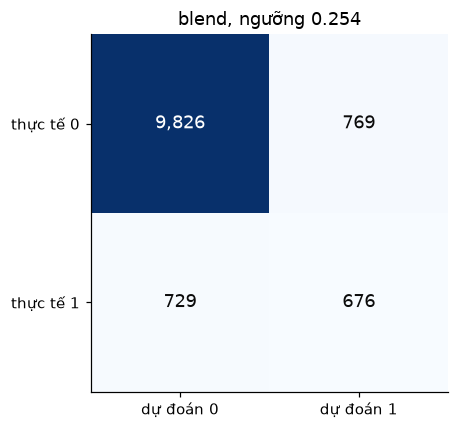

In [9]:
threshold = best_f1_threshold(y, oof[BEST])
threshold_table = pd.DataFrame([label_metrics(y, oof[BEST], t) for t in [0.1, 0.15, 0.2, 0.3, 0.5, threshold]])
threshold_table.to_csv(OUT / 'threshold_metrics.csv', index=False)
display(threshold_table.round(3))

cm = confusion_matrix(y, (oof[BEST] >= threshold).astype(int), labels=[0, 1])
fig, ax = plt.subplots(figsize=(4.6, 4))
ax.imshow(cm, cmap='Blues')
ax.grid(False)
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, f'{v:,}', ha='center', va='center', color='white' if v > cm.max() / 2 else '#0b0b0b', fontsize=12)
ax.set_xticks([0, 1], ['dự đoán 0', 'dự đoán 1'])
ax.set_yticks([0, 1], ['thực tế 0', 'thực tế 1'])
ax.set_title(f'{BEST}, ngưỡng {threshold:.3f}')
fig.tight_layout()
fig.savefig(OUT / 'confusion_matrix.png', bbox_inches='tight')
plt.show()

## 7. Yếu tố ảnh hưởng (permutation importance)

Xáo trộn từng cột trên phần validation của fold 1 và đo AUC giảm bao nhiêu. Giảm nhiều → mô hình dựa nhiều vào cột đó.
Đây là mức độ **mô hình dùng** cột, không phải quan hệ nhân quả.

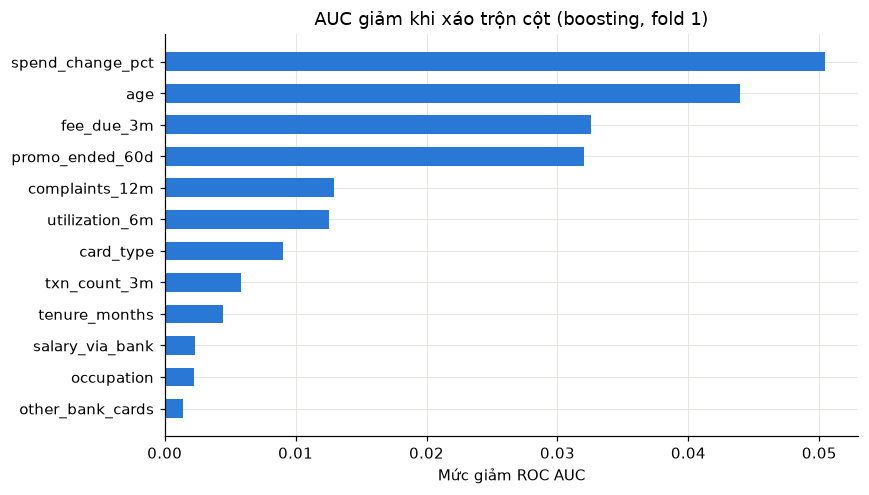

In [10]:
tr, va = folds[0]
_, boost = fit_predict(tr, (raw_X.iloc[va], X.iloc[va]))
result = permutation_importance(boost, X.iloc[va], y[va], scoring='roc_auc', n_repeats=5, random_state=SEED)
importance = (pd.DataFrame({'feature': X.columns, 'auc_drop': result.importances_mean, 'std': result.importances_std})
              .sort_values('auc_drop', ascending=False).reset_index(drop=True))
importance.to_csv(OUT / 'feature_importance.csv', index=False)

top = importance.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(top.feature, top.auc_drop, color=COLORS[0], height=0.6)
ax.set(title='AUC giảm khi xáo trộn cột (boosting, fold 1)', xlabel='Mức giảm ROC AUC')
fig.tight_layout()
fig.savefig(OUT / 'feature_importance.png', bbox_inches='tight')
plt.show()

## 8. Train trên toàn bộ dữ liệu và ghi 2 submission

- `submission_1_boosting.csv` — HistGradientBoosting
- `submission_2_blend.csv` — 0.8 boosting + 0.2 logistic

Không có bước ngẫu nhiên nào ngoài seed cố định, nên chạy lại cho ra đúng hai file này.

In [11]:
def save_submission(prob, filename):
    assert sample.columns.tolist() == [ID, TARGET], 'sample_submission có cột không như mong đợi'
    assert test[ID].is_unique and set(test[ID]) == set(sample[ID]), 'ID test và sample_submission không khớp'
    assert np.isfinite(prob).all() and ((prob >= 0) & (prob <= 1)).all(), 'xác suất phải nằm trong [0, 1]'
    result = sample[[ID]].merge(pd.DataFrame({ID: test[ID], TARGET: prob}), on=ID, how='left', validate='one_to_one')
    result.to_csv(OUT / filename, index=False)
    print(f'Đã ghi {OUT / filename}: {result.shape}')
    return result


if test is None:
    print('CHƯA CÓ test.csv — chạy notebook trên Kaggle (Add Input cuộc thi) để tạo submission.')
else:
    X_test = clean(test)
    assert list(X_test.columns) == list(X.columns), 'Cột train/test không khớp sau làm sạch'
    test_probs, _ = fit_predict(np.arange(len(X)), (test.drop(columns=ID), X_test))
    save_submission(test_probs['boosting'], 'submission_1_boosting.csv')
    display(save_submission(test_probs['blend'], 'submission_2_blend.csv').head())

CHƯA CÓ test.csv — chạy notebook trên Kaggle (Add Input cuộc thi) để tạo submission.


## 9. Gợi ý cho quyết định kinh doanh

**Bảng lift:** xếp khách theo rủi ro dự đoán (OOF), chia 10 nhóm. Nếu ngân hàng chỉ đủ nguồn lực liên hệ 10–20% khách,
bảng cho biết sẽ tiếp cận được bao nhiêu % khách sắp đóng thẻ. Lưu ở `lift_table.csv`.

In [12]:
decile = pd.qcut(oof[BEST].rank(method='first', ascending=False), 10, labels=range(1, 11))
lift = oof.groupby(decile, observed=True).actual.agg(customers='size', churners='sum')
lift['churn_rate_%'] = 100 * lift.churners / lift.customers
lift['cum_customers_%'] = 100 * lift.customers.cumsum() / lift.customers.sum()
lift['cum_churners_captured_%'] = 100 * lift.churners.cumsum() / lift.churners.sum()
lift['lift'] = lift['churn_rate_%'] / (100 * y.mean())
lift.index.name = 'decile (1 = rủi ro cao nhất)'
lift.to_csv(OUT / 'lift_table.csv')
display(lift.round(2))

drivers = pd.DataFrame({
    'phí thường niên đến hạn trong 3 tháng': X.fee_due_3m.eq(1),
    'khuyến mãi vừa kết thúc (60 ngày)': X.promo_ended_60d.eq(1),
    'có khiếu nại trong 12 tháng': X.complaints_12m.gt(0),
    'chi tiêu giảm > 30%': X.spend_change_pct.lt(-30),
    'chi tiêu ròng âm': X.txn_amount_3m.lt(0),
    'không đăng nhập app 30 ngày': X.app_logins_30d.eq(0),
})
driver_table = pd.DataFrame({'customers': drivers.sum(),
                             'churn_%_if_yes': [100 * y[drivers[c]].mean() for c in drivers],
                             'churn_%_if_no': [100 * y[~drivers[c]].mean() for c in drivers]}).round(1)
display(driver_table)
driver_table.to_csv(OUT / 'churn_drivers.csv')

if test is not None:
    cut_high, cut_mid = np.quantile(oof[BEST], [0.9, 0.7])
    risk = test[[ID]].assign(churn_probability=test_probs[BEST])
    risk['segment'] = np.select([risk.churn_probability >= cut_high, risk.churn_probability >= cut_mid],
                                ['cao (top 10%)', 'trung bình (top 10–30%)'], 'thấp')
    risk = risk.sort_values('churn_probability', ascending=False)
    risk.to_csv(OUT / 'test_risk_ranking.csv', index=False)
    print('Số khách test theo nhóm rủi ro (ngưỡng lấy từ phân phối OOF):')
    display(risk.segment.value_counts().to_frame('customers'))

,customers,churners,churn_rate_%,cum_customers_%,cum_churners_captured_%,lift
decile (1 = rủi ro cao nhất),,,,,,
1,1200,605,50.42,10.0,43.06,4.31
2,1200,273,22.75,20.0,62.49,1.94
3,1200,157,13.08,30.0,73.67,1.12
4,1200,86,7.17,40.0,79.79,0.61
5,1200,75,6.25,50.0,85.12,0.53
6,1200,48,4.00,60.0,88.54,0.34
7,1200,50,4.17,70.0,92.10,0.36
8,1200,49,4.08,80.0,95.59,0.35
9,1200,30,2.50,90.0,97.72,0.21


,customers,churn_%_if_yes,churn_%_if_no
phí thường niên đến hạn trong 3 tháng,1462,25.2,9.8
khuyến mãi vừa kết thúc (60 ngày),2345,20.9,9.5
có khiếu nại trong 12 tháng,2654,17.2,10.1
chi tiêu giảm > 30%,1401,24.3,10.0
chi tiêu ròng âm,169,23.7,11.5
không đăng nhập app 30 ngày,226,22.6,11.5


## File kết quả

| File | Nội dung |
|---|---|
| `data_quality.csv` | Số lượng từng loại lỗi, train và test |
| `train_clean.csv` | train sau làm sạch (đã bỏ trùng) |
| `cv_metrics_by_fold.csv` | AUC, PR AUC, log loss, Brier theo fold × mô hình |
| `cv_metrics_summary.csv` | Toàn bộ chỉ số: AUC, accuracy, precision, recall, F1… ở ngưỡng 0.5 và ngưỡng tối ưu F1 |
| `oof_predictions.csv` | Xác suất OOF của từng mô hình cho từng khách |
| `threshold_metrics.csv` | Chỉ số theo nhiều ngưỡng của mô hình tốt nhất |
| `feature_importance.csv`, `churn_drivers.csv` | Yếu tố ảnh hưởng và tỷ lệ churn theo từng dấu hiệu |
| `lift_table.csv` | % khách churn tiếp cận được khi liên hệ top-k% khách rủi ro |
| `submission_1_boosting.csv`, `submission_2_blend.csv` | Hai file nộp Kaggle |
| `test_risk_ranking.csv` | Khách test xếp theo rủi ro, chia nhóm cao / trung bình / thấp |

Điểm CV là ước lượng nội bộ; điểm thật là private leaderboard.